#Group 1
#####Nkululeko Kubheka : 2026286373
#####Akho Mbonjwa : 2025236890
#####Tshidiso Moate : 2021220846
#####Lekoba Moraba : 2025874641
#####Tholoana Mosane : 2026547972
#####Londeka Mthembu : 2020372542
#####Keoreeditse Selibi : 2025200300

#Assignment 2
##Credit Scoring under Class Imbalance: Out-of-Sample and Out-of-Time Evaluation


#Part A
##Data Understanding

#1. Import libraries

In [ ]:
#Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute  import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    average_precision_score,
    classification_report,
    roc_curve,
    precision_recall_curve
    )
#Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#2. Load the dataset in Colab

In [ ]:
#Load datasets
training_data = pd.read_csv('training.csv')
OOS_data = pd.read_csv('OOS test.csv')
OOT_data = pd.read_csv('OOT test.csv')
#Display dataset dimensions
print("Training dataset shape:", training_data.shape)
print("OOS dataset shape:", OOS_data.shape)
print("OOT dataset shape:", OOT_data.shape)

print("Training dataset:")
display(training_data.head())

print("OOS dataset:")
display(OOS_data.head())

print("OOT dataset:")
display(OOT_data.head())


Training dataset shape: (231064, 80)
OOS dataset shape: (232515, 80)
OOT dataset shape: (352788, 80)
Training dataset:


,Loanref,Credit_Score,Mortgage_Insurance,Number_of_units,CLoan_to_value,Debt_to_income,OLoan_to_value,Single_borrower,is_Loan_purpose_purc,is_Loan_purpose_cash,...,is_property_state_TX,is_property_state_UT,is_property_state_VA,is_property_state_VI,is_property_state_VT,is_property_state_WA,is_property_state_WI,is_property_state_WV,is_property_state_WY,DFlag
0,F116Q3164706,723,30,1,95.0,44.0,95.0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,F116Q3287992,728,0,1,74.0,27.0,74.0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
2,F116Q1171011,708,0,1,78.0,28.0,78.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,F116Q4133195,666,0,1,38.0,24.0,38.0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,F116Q4268992,679,0,1,80.0,45.0,80.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


OOS dataset:


,Loanref,Credit_Score,Mortgage_Insurance,Number_of_units,CLoan_to_value,Debt_to_income,OLoan_to_value,Single_borrower,is_Loan_purpose_purc,is_Loan_purpose_cash,...,is_property_state_TX,is_property_state_UT,is_property_state_VA,is_property_state_VI,is_property_state_VT,is_property_state_WA,is_property_state_WI,is_property_state_WV,is_property_state_WY,DFlag
0,F116Q2146206,709,0,1,70.0,22.0,70.0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,F116Q1210385,688,30,1,95.0,28.0,95.0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,F116Q1043395,694,0,1,69.0,46.0,69.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,F116Q1216050,662,0,1,72.0,29.0,72.0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,F116Q3382757,681,0,1,75.0,44.0,75.0,0,0,1,...,1,0,0,0,0,0,0,0,0,0


OOT dataset:


,Loanref,Credit_Score,Mortgage_Insurance,Number_of_units,CLoan_to_value,Debt_to_income,OLoan_to_value,Single_borrower,is_Loan_purpose_purc,is_Loan_purpose_cash,...,is_property_state_TX,is_property_state_UT,is_property_state_VA,is_property_state_VI,is_property_state_VT,is_property_state_WA,is_property_state_WI,is_property_state_WV,is_property_state_WY,DFlag
0,F118Q1000003,726,0.0,1,46.0,15.0,46.0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,F118Q1000004,678,0.0,1,72.0,39.0,72.0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,F118Q1000006,723,0.0,1,74.0,32.0,74.0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,F118Q1000011,722,0.0,1,69.0,34.0,69.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,F118Q1000012,698,0.0,1,59.0,36.0,59.0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


###Purpose of the datasets

The training dataset is used for modeling development, including training, validation, hyperparameter tuning and decision-threshold selection.

The OOS dataset is reserved for final out-of-sample evaluation on unseen observations from simlar timline to the training data.

The OOT dataset contains observations from a later timeline and is used to evaluate whether the modle remains reliable over time.

#3. Understanding the data set

In [ ]:
#understanding the data
training_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231064 entries, 0 to 231063
Data columns (total 80 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loanref                       231064 non-null  object 
 1   Credit_Score                  231064 non-null  int64  
 2   Mortgage_Insurance            231064 non-null  int64  
 3   Number_of_units               231064 non-null  int64  
 4   CLoan_to_value                231061 non-null  float64
 5   Debt_to_income                231054 non-null  float64
 6   OLoan_to_value                231061 non-null  float64
 7   Single_borrower               231064 non-null  int64  
 8   is_Loan_purpose_purc          231064 non-null  int64  
 9   is_Loan_purpose_cash          231064 non-null  int64  
 10  is_Loan_purpose_noca          231064 non-null  int64  
 11  is_First_time_homeowner       231064 non-null  int64  
 12  is_First_time_homeowner_No    231064 non-nul

In [ ]:
OOS_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232515 entries, 0 to 232514
Data columns (total 80 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loanref                       232515 non-null  object 
 1   Credit_Score                  232515 non-null  int64  
 2   Mortgage_Insurance            232515 non-null  int64  
 3   Number_of_units               232515 non-null  int64  
 4   CLoan_to_value                232512 non-null  float64
 5   Debt_to_income                232504 non-null  float64
 6   OLoan_to_value                232512 non-null  float64
 7   Single_borrower               232515 non-null  int64  
 8   is_Loan_purpose_purc          232515 non-null  int64  
 9   is_Loan_purpose_cash          232515 non-null  int64  
 10  is_Loan_purpose_noca          232515 non-null  int64  
 11  is_First_time_homeowner       232515 non-null  int64  
 12  is_First_time_homeowner_No    232515 non-nul

In [ ]:
OOT_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 352788 entries, 0 to 352787
Data columns (total 80 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loanref                       352788 non-null  object 
 1   Credit_Score                  352788 non-null  int64  
 2   Mortgage_Insurance            352786 non-null  float64
 3   Number_of_units               352788 non-null  int64  
 4   CLoan_to_value                352778 non-null  float64
 5   Debt_to_income                352768 non-null  float64
 6   OLoan_to_value                352778 non-null  float64
 7   Single_borrower               352788 non-null  int64  
 8   is_Loan_purpose_purc          352788 non-null  int64  
 9   is_Loan_purpose_cash          352788 non-null  int64  
 10  is_Loan_purpose_noca          352788 non-null  int64  
 11  is_First_time_homeowner       352788 non-null  int64  
 12  is_First_time_homeowner_No    352788 non-nul

##4. Predictor column alignment across training, OOS and OOT

In [ ]:
training_columns = set(training_data.columns)
OOS_columns = set(OOS_data.columns)
OOT_columns = set(OOT_data.columns)

print("Training vs OOS columns:", training_columns == OOS_columns)
print("Training vs OOT columns:", training_columns == OOT_columns)
print("OOS vs OOT columns:", OOS_columns == OOT_columns)

Training vs OOS columns: True
Training vs OOT columns: True
OOS vs OOT columns: True


In [ ]:
# Check that all columns have the same names and order
assert (
    list(training_data.columns)
    == list(OOS_data.columns)
    == list(OOT_data.columns)
), "Column mismatch detected!"

print("All 80 columns are aligned across training, OOS and OOT.")

All 80 columns are aligned across training, OOS and OOT.


#5. Data Cleaning

###- We checked for duplicate rows and there were no duplicates found
###Missing values were also checked and we found 16 from the training file, 17 from the OOS file and 42 missing values from the OOT file
###- To fill in the missing values we replaced the missing values with median imputations for the continuous variables. Median imputation gives us a central value without being heavily affected by extreme observations.
###-To prevent data leakage that would affect modeling, the median used was calculated from the training dataset


In [ ]:
#Check for duplicates
duplicate_count = training_data.duplicated().sum()
print("Number of duplicate rows in the training dataset:", duplicate_count)

duplicate_count = OOS_data.duplicated().sum()
print("Number of duplicate rows in the OOS dataset:", duplicate_count)

duplicate_count = OOT_data.duplicated().sum()
print("Number of duplicate rows in the OOT dataset:", duplicate_count)

Number of duplicate rows in the training dataset: 0
Number of duplicate rows in the OOS dataset: 0
Number of duplicate rows in the OOT dataset: 0


In [ ]:
# Display columns that have at least 1 missing value
print("Training missing columns:")
print(training_data.isnull().sum()[training_data.isnull().sum() > 0])

print("\nOOS missing columns:")
print(OOS_data.isnull().sum()[OOS_data.isnull().sum() > 0])

print("\nOOT missing columns:")
print(OOT_data.isnull().sum()[OOT_data.isnull().sum() > 0])

Training missing columns:
CLoan_to_value     3
Debt_to_income    10
OLoan_to_value     3
dtype: int64

OOS missing columns:
CLoan_to_value     3
Debt_to_income    11
OLoan_to_value     3
dtype: int64

OOT missing columns:
Mortgage_Insurance     2
CLoan_to_value        10
Debt_to_income        20
OLoan_to_value        10
dtype: int64


In [ ]:
# Fill missing values using medians calculated from the TRAINING file only

missing_cols = ['CLoan_to_value', 'Debt_to_income', 'OLoan_to_value', 'Mortgage_Insurance']

#compute the median of each column, using training data only
train_medians = training_data[missing_cols].median()

#fill blanks in all three files with those training medians
training_data[missing_cols] = training_data[missing_cols].fillna(train_medians)
OOS_data[missing_cols]      = OOS_data[missing_cols].fillna(train_medians)
OOT_data[missing_cols]      = OOT_data[missing_cols].fillna(train_medians)

#verify — should print 0 for all three
print("Missing after cleaning:")
print("  Training:", training_data.isnull().sum().sum())
print("  OOS     :", OOS_data.isnull().sum().sum())
print("  OOT     :", OOT_data.isnull().sum().sum())

Missing after cleaning:
  Training: 0
  OOS     : 0
  OOT     : 0


#6. Inspecting the target variable "DFlag"

In [ ]:
#Inspect the target variable
print("0 = No Default \n1 = Default")

print("\nTraining label:")
print(training_data["DFlag"].value_counts())

print("\nOOS label:")
print(OOS_data["DFlag"].value_counts())

print("\nOOT label:")
print(OOT_data["DFlag"].value_counts())

0 = No Default 
1 = Default

Training label:
DFlag
0    230473
1       591
Name: count, dtype: int64

OOS label:
DFlag
0    231919
1       596
Name: count, dtype: int64

OOT label:
DFlag
0    351862
1       926
Name: count, dtype: int64


#7. Calculating Imbalance Ratios

In [ ]:
print("\nTraining label percentages:")
print((training_data["DFlag"].value_counts(normalize=True) * 100).round(3))

print("\nOOS label percentages:")
print((OOS_data["DFlag"].value_counts(normalize=True) * 100).round(3))

print("\nOOT label percentages:")
print((OOT_data["DFlag"].value_counts(normalize=True) * 100).round(3))



Training label percentages:
DFlag
0    99.744
1     0.256
Name: proportion, dtype: float64

OOS label percentages:
DFlag
0    99.744
1     0.256
Name: proportion, dtype: float64

OOT label percentages:
DFlag
0    99.738
1     0.262
Name: proportion, dtype: float64


In [ ]:
# Calculate imbalance ratio for Training data
non_defaults_train = (training_data["DFlag"] == 0).sum()
defaults_train = (training_data["DFlag"] == 1).sum()
imbalance_ratio_train = round(non_defaults_train / defaults_train, 2)

print("Training Imbalance Ratio:", imbalance_ratio_train)
print("Training Non-defaults:", non_defaults_train)
print("Training Defaults:", defaults_train)


# Calculate imbalance ratio for OOS data
non_defaults_OOS = (OOS_data["DFlag"] == 0).sum()
defaults_OOS = (OOS_data["DFlag"] == 1).sum()
imbalance_ratio_OOS = round(non_defaults_OOS / defaults_OOS, 2)

print("\nOOS Imbalance Ratio:", imbalance_ratio_OOS)
print("OOS Non-defaults:", non_defaults_OOS)
print("OOS Defaults:", defaults_OOS)


# Calculate imbalance ratio for OOT data
non_defaults_OOT = (OOT_data["DFlag"] == 0).sum()
defaults_OOT = (OOT_data["DFlag"] == 1).sum()
imbalance_ratio_OOT = round(non_defaults_OOT / defaults_OOT, 2)

print("\nOOT Imbalance Ratio:", imbalance_ratio_OOT)
print("OOT Non-defaults:", non_defaults_OOT)
print("OOT Defaults:", defaults_OOT)

Training Imbalance Ratio: 389.97
Training Non-defaults: 230473
Training Defaults: 591

OOS Imbalance Ratio: 389.13
OOS Non-defaults: 231919
OOS Defaults: 596

OOT Imbalance Ratio: 379.98
OOT Non-defaults: 351862
OOT Defaults: 926


In [ ]:
print("Class distribution across all three files\n")
print(f"{'File':10s} {'Non-defaults':>14s} {'Defaults':>10s} {'Default %':>12s} {'Imbalance ratio':>18s}")
print("-" * 70)

for name, df in [("Training", training_data), ("OOS", OOS_data), ("OOT", OOT_data)]:
    n0    = (df["DFlag"] == 0).sum()
    n1    = (df["DFlag"] == 1).sum()
    pct   = n1 / (n0 + n1) * 100
    ratio = n0 / n1
    print(f"{name:10s} {n0:>14,} {n1:>10,} {pct:>11.3f}% {ratio:>17.2f} : 1")

Class distribution across all three files

File         Non-defaults   Defaults    Default %    Imbalance ratio
----------------------------------------------------------------------
Training          230,473        591       0.256%            389.97 : 1
OOS               231,919        596       0.256%            389.13 : 1
OOT               351,862        926       0.262%            379.98 : 1


In [ ]:
#Display all column names
for column in training_data.columns:
    print(column)

Loanref
Credit_Score
Mortgage_Insurance
Number_of_units
CLoan_to_value
Debt_to_income
OLoan_to_value
Single_borrower
is_Loan_purpose_purc
is_Loan_purpose_cash
is_Loan_purpose_noca
is_First_time_homeowner
is_First_time_homeowner_No
is_First_time_homeowner_miss
is_Occupancy_status_prim
is_Occupancy_status_inve
is_Occupancy_status_seco
is_Origination_channel_reta
is_Origination_channel_brok
is_Origination_channel_corr
is_Property_type_cond
is_Property_type_coop
is_Property_type_manu
is_Property_type_pud
is_Property_type_sing
is_property_state_AK
is_property_state_AL
is_property_state_AR
is_property_state_AZ
is_property_state_CA
is_property_state_CO
is_property_state_CT
is_property_state_DC
is_property_state_DE
is_property_state_FL
is_property_state_GA
is_property_state_GU
is_property_state_HI
is_property_state_IA
is_property_state_ID
is_property_state_IL
is_property_state_IN
is_property_state_KS
is_property_state_KY
is_property_state_LA
is_property_state_MA
is_property_state_MD
is_propert

#8. Selecting Important Variables
###We selected the following variables:
#####- Credit Score: It represents borrower's credit score and we selected it because it may be associated with lower creditworthiness and may indicate greater repayment risk.
#####- Debt to income: It represents debt relative to income and may be associated with higher debt burden and may make repayment more difficult.
#####- CLoan to value: It represents loan to value measure. It may be associated with higher leverage and can increase lender exposure.
#####- OLoan to value: It represents another loan to value measure and provides additional information about property or loan leverage.
#####- Mortgage Insurance: Represents mortgage insurance. It distinguishes loans with different risk characteristics.
#####- Number of units: Represents number of units in the property. Property characteristics may be associated with different risk profiles.
#####- Single borrower: Represents whether the loan has a single borrower. Borrower structure can be associated with repayment capacity.
#####- is First time homeowner: Indicates first time homeowners. First time buyers may have different financial or risk characteristics.
#####- is Occupancy status pr: Indicates primary residence. Ocupancy type can be associated with borrower behaviour.
#####- is occupancy status inve: Indicates investment-property. Investment-properties represent a different lending context.

In [ ]:
important_variables = [
    "Credit_Score",
    "Mortgage_Insurance",
    "Number_of_units",
    "CLoan_to_value",
    "Debt_to_income",
    "OLoan_to_value",
    "Single_borrower",
    "is_Loan_purpose_purc",
    "is_Loan_purpose_cash",
    "is_First_time_homeowner",
    "is_Occupancy_status_prim",
    "is_Occupancy_status_inve",
    "is_Origination_channel_reta",
    "is_Origination_channel_brok",
    "is_Property_type_pud"
]

#Part B

#1. Defaults vs Non-defaults







Default Counts
DFlag
0    230473
1       591
Name: count, dtype: int64




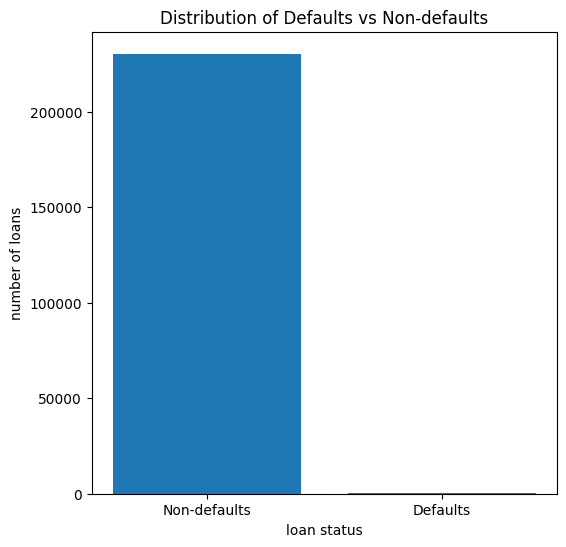

In [ ]:
#Count the  observations in each target class
print("Default Counts")
defaults_counts = training_data["DFlag"].value_counts()
print(defaults_counts)

#Create a bar chart

labels = ["Non-defaults", "Defaults"]
counts = [
    (training_data["DFlag"] == 0).sum(),
    (training_data["DFlag"] == 1).sum()
]

print("\n")
plt.figure(figsize=(6, 6))
plt.bar(labels, counts)
plt.title("Distribution of Defaults vs Non-defaults")
plt.xlabel("loan status")
plt.ylabel("number of loans")
plt.show()

Default Percentages:
DFlag
0    99.74
1     0.26
Name: proportion, dtype: float64




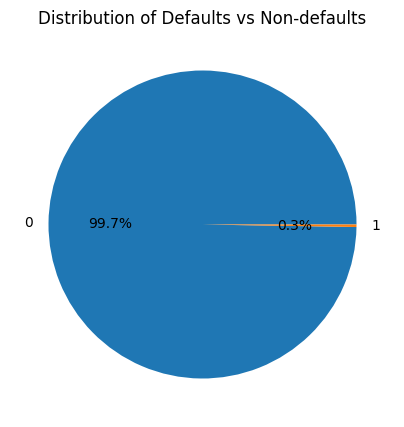

In [ ]:
#Calculate percentages for each target class
default_percentages = (training_data["DFlag"].value_counts(normalize=True) * 100).round(2)
print("Default Percentages:")
print(default_percentages)

print("\n")

plt.figure(figsize=(5, 5))
plt.pie(default_percentages, labels=default_percentages.index, autopct='%1.1f%%')
plt.title("Distribution of Defaults vs Non-defaults")
plt.show()

#2. Numerical Variables vs Default

In [ ]:
#Do borrower who default appear different from who don't default in these risk variables?

#Compare summary statistics
numerical_variables = [
    "Credit_Score",
    "CLoan_to_value",
    "Debt_to_income",
    "OLoan_to_value"
]

training_data.groupby("DFlag")[numerical_variables].agg(["count","mean", "median", "std", "min", "max"])


Credit_Score                                         CLoan_to_value  \
             count        mean median        std  min  max          count   
DFlag                                                                       
0           230473  695.053338  701.0  25.735180  599  729         230473   
1              591  678.152284  680.0  30.623695  601  729            591   

                                    ... Debt_to_income                       \
            mean median        std  ...         median       std  min   max   
DFlag                               ...                                       
0      75.135777   80.0  15.361231  ...           37.0  8.445849  1.0  50.0   
1      79.037225   80.0  14.121337  ...           40.0  7.480529  5.0  50.0   

      OLoan_to_value                                           
               count       mean median        std   min   max  
DFlag                                                          
0             230473  74.690532   79.0  15.451502   6.0  95.0  
1                591  78.614213   80.0  14.284402  22.0  95.0  

[2 rows x 24 columns]

<Figure size 800x600 with 0 Axes>

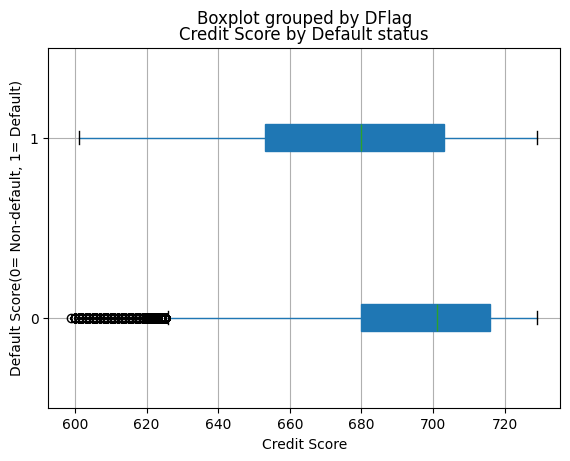

In [ ]:
#Visualise
#Credit score
plt.figure(figsize=(8, 6))

training_data.boxplot(
    column= "Credit_Score",
    by= "DFlag",
    vert= False,
    patch_artist= True
)

plt.title("Credit Score by Default status")
plt.xlabel("Credit Score")
plt.ylabel("Default Score(0= Non-default, 1= Default)")
plt.show()

<Figure size 800x600 with 0 Axes>

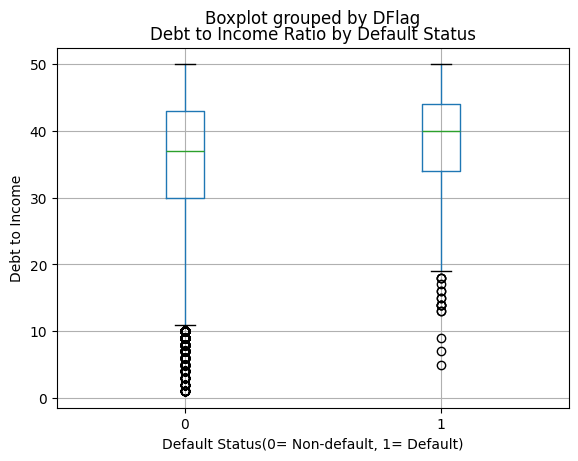

In [ ]:
#Visualise
#Debt to income

plt.figure(figsize=(8, 6))

training_data.boxplot(
    column= "Debt_to_income",
    by= "DFlag"
)

plt.title("Debt to Income Ratio by Default Status")
plt.xlabel("Default Status(0= Non-default, 1= Default)")
plt.ylabel("Debt to Income")
plt.show()


<Figure size 800x600 with 0 Axes>

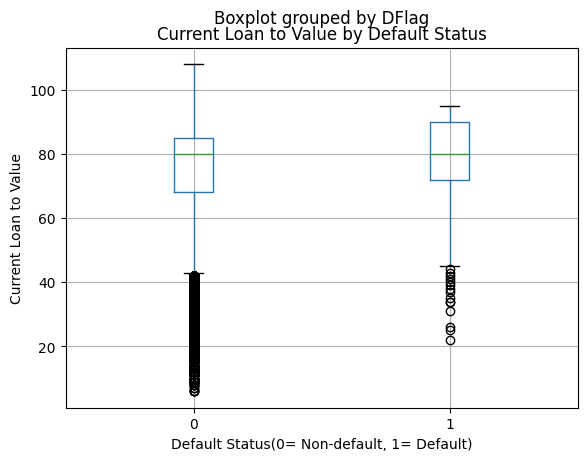

In [ ]:
#Visualise
#Current loan to Value

plt.figure(figsize=(8, 6))

training_data.boxplot(
    column= "CLoan_to_value",
    by= "DFlag"
)

plt.title("Current Loan to Value by Default Status")
plt.xlabel("Default Status(0= Non-default, 1= Default)")
plt.ylabel("Current Loan to Value")
plt.show()

<Figure size 800x600 with 0 Axes>

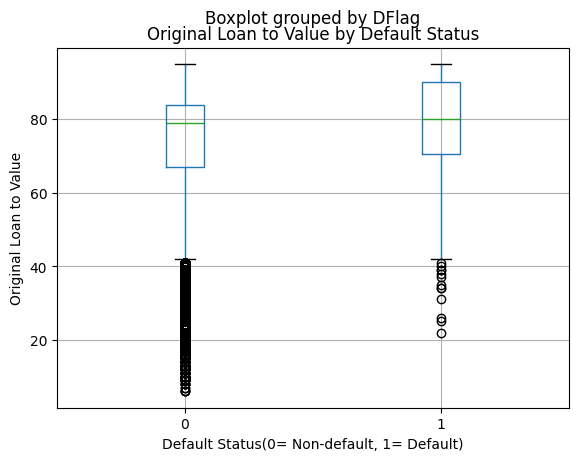

In [ ]:
#Visualize
#Original loan to Value

plt.figure(figsize=(8, 6))

training_data.boxplot(
    column= "OLoan_to_value",
    by= "DFlag"
)

plt.title("Original Loan to Value by Default Status")
plt.xlabel("Default Status(0= Non-default, 1= Default)")
plt.ylabel("Original Loan to Value")
plt.show()

#3. Indicator variables and Default rates
###Does the behaviour differ between different loan groups?
###Groups:
#####1. Loan purpose
#####2. First time homeowner
#####3. Occupance status
#####4. Origination channel


In [ ]:
#Loan Purpose

loan_purpose_columns = [
    col for col in training_data.columns
    if "Loan_purpose" in col
]
print(loan_purpose_columns)

print("\n")

#calculate th edefault rate for each category
for column in loan_purpose_columns:
  default_rate = (training_data.loc[training_data[column]==1, "DFlag"].mean() * 100).round(2)

  print(f"{column:}: {default_rate:.3f}%")

['is_Loan_purpose_purc', 'is_Loan_purpose_cash', 'is_Loan_purpose_noca']


is_Loan_purpose_purc: 0.320%
is_Loan_purpose_cash: 0.240%
is_Loan_purpose_noca: 0.160%


In [ ]:
#First Time Homeowners

homeowner_columns = [
    col for col in training_data.columns
    if "First_time_homeowner" in col
]
print(homeowner_columns)

print("\n")

#calculate th edefault rate for each category
for column in homeowner_columns:
  default_rate = (training_data.loc[training_data[column]==1, "DFlag"].mean() * 100).round(2)

  print(f"{column:}: {default_rate:.3f}%")

['is_First_time_homeowner', 'is_First_time_homeowner_No', 'is_First_time_homeowner_miss']


is_First_time_homeowner: 0.350%
is_First_time_homeowner_No: 0.340%
is_First_time_homeowner_miss: 0.200%


In [ ]:
#Occupancy status

occupancy_columns = [
    col for col in training_data.columns
    if "Occupancy_status" in col
]

print(occupancy_columns)

print("\n")

#calculate th edefault rate for each category
for column in occupancy_columns:
  default_rate = (training_data.loc[training_data[column]==1, "DFlag"].mean() * 100).round(2)

  print(f"{column:}: {default_rate:.3f}%")

['is_Occupancy_status_prim', 'is_Occupancy_status_inve', 'is_Occupancy_status_seco']


is_Occupancy_status_prim: 0.270%
is_Occupancy_status_inve: 0.130%
is_Occupancy_status_seco: 0.090%


In [ ]:
#Origination channel

origination_columns = [
    col for col in training_data.columns
    if "Origination_channel" in col
]

print(origination_columns)

print("\n")

#calculate th edefault rate for each category
for column in origination_columns:
  default_rate = (training_data.loc[training_data[column]==1, "DFlag"].mean() * 100).round(2)

  print(f"{column:}: {default_rate:.3f}%")

['is_Origination_channel_reta', 'is_Origination_channel_brok', 'is_Origination_channel_corr']


is_Origination_channel_reta: 0.230%
is_Origination_channel_brok: 0.300%
is_Origination_channel_corr: 0.300%


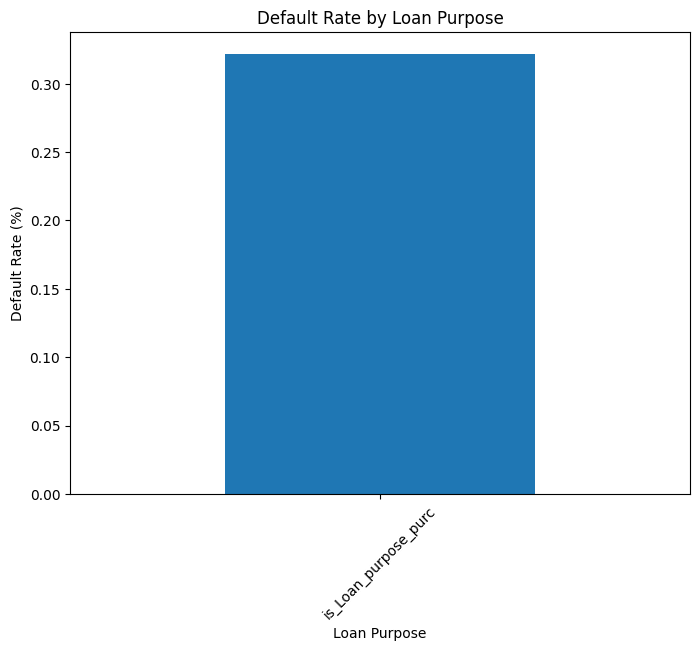

In [ ]:
#Visualisation
#calculations
def calculate_default_rate(df, columns):
  results = {}

  for column in columns:
    results[column] = training_data.loc[training_data[column]==1, "DFlag"].mean() *100

    return pd.Series(results).sort_values(ascending=False)


loan_purpose_rates = calculate_default_rate(training_data, loan_purpose_columns)
loan_purpose_rates

#ploting
plt.figure(figsize=(8, 6))

loan_purpose_rates.plot(kind="bar")

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.show()

#4. Comparison: Training OOS vs OOT


In [ ]:
#Comparison Variables
comparison_variables = [
    "Credit_Score",
    "Mortgage_Insurance",
    "CLoan_to_value",
    "Debt_to_income",
    "OLoan_to_value"
]

In [ ]:
#Summary table
#Comparing means
comparison_summary = pd.DataFrame(
    {
        "Training": training_data[comparison_variables].mean(),
        "OOS": OOS_data[comparison_variables].mean(),
        "OOT": OOT_data[comparison_variables].mean()
    }
)

comparison_summary.round(2)


,Training,OOS,OOT
Credit_Score,695.01,694.97,692.59
Mortgage_Insurance,6.69,6.69,7.37
CLoan_to_value,75.15,75.16,75.21
Debt_to_income,35.84,35.86,37.10
OLoan_to_value,74.70,74.71,74.96


In [ ]:
#Summary table
#Comparing medians
comparison_summary_medians = pd.DataFrame(
    {
        "Training": training_data[comparison_variables].median(),
        "OOS": OOS_data[comparison_variables].median(),
        "OOT": OOT_data[comparison_variables].median()
    }
)

comparison_summary_medians.round(2)

,Training,OOS,OOT
Credit_Score,701.0,700.0,699.0
Mortgage_Insurance,0.0,0.0,0.0
CLoan_to_value,80.0,80.0,80.0
Debt_to_income,37.0,37.0,39.0
OLoan_to_value,79.0,79.0,80.0


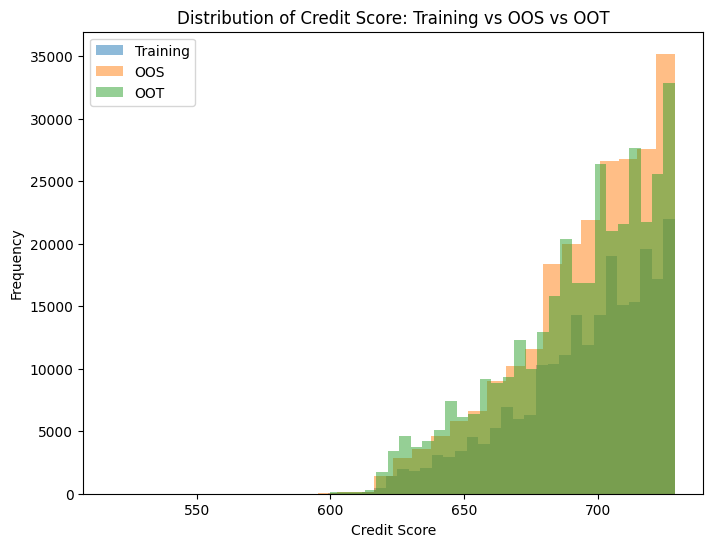

In [ ]:
#Comparing distribustions visually
#Credit Score
plt.figure(figsize=(8, 6))

plt.hist(
    training_data["Credit_Score"].dropna(),
    bins=30,
    alpha=0.5,
    label="Training"
)

plt.hist(
    OOS_data["Credit_Score"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOS"
)

plt.hist(
    OOT_data["Credit_Score"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOT"
)

plt.title("Distribution of Credit Score: Training vs OOS vs OOT")
plt.xlabel("Credit Score")
plt.ylabel("Frequency")
plt.legend()
plt.show()

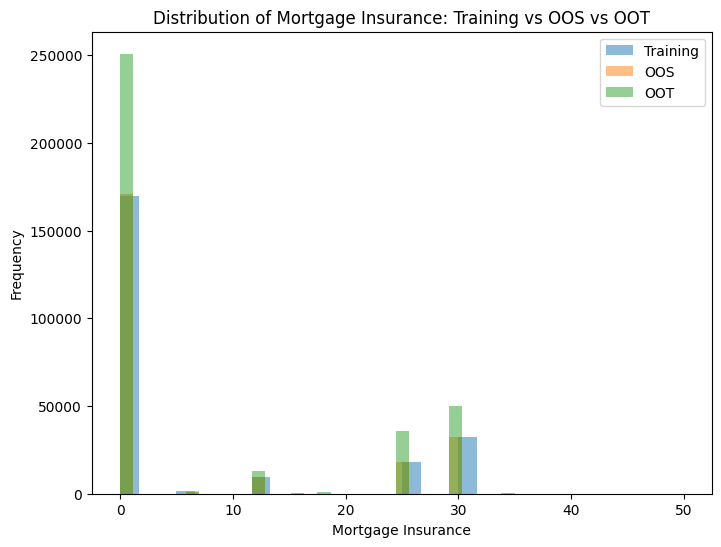

In [ ]:
#Comparing distribustions visually
#Mortgage_Insurance

plt.figure(figsize=(8, 6))

plt.hist(
    training_data["Mortgage_Insurance"].dropna(),
    bins=30,
    alpha=0.5,
    label="Training"
)

plt.hist(
    OOS_data["Mortgage_Insurance"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOS"
)

plt.hist(
    OOT_data["Mortgage_Insurance"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOT"
)

plt.title("Distribution of Mortgage Insurance: Training vs OOS vs OOT")
plt.xlabel("Mortgage Insurance")
plt.ylabel("Frequency")
plt.legend()
plt.show()

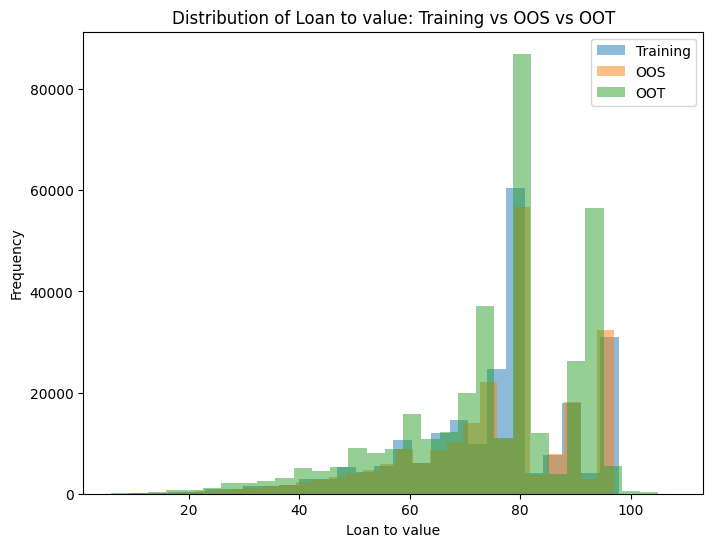

In [ ]:
#Comparing distribustions visually
#CLoan_to_value

plt.figure(figsize=(8, 6))

plt.hist(
    training_data["CLoan_to_value"].dropna(),
    bins=30,
    alpha=0.5,
    label="Training"
)

plt.hist(
    OOS_data["CLoan_to_value"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOS"
)

plt.hist(
    OOT_data["CLoan_to_value"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOT"
)

plt.title("Distribution of Loan to value: Training vs OOS vs OOT")
plt.xlabel("Loan to value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

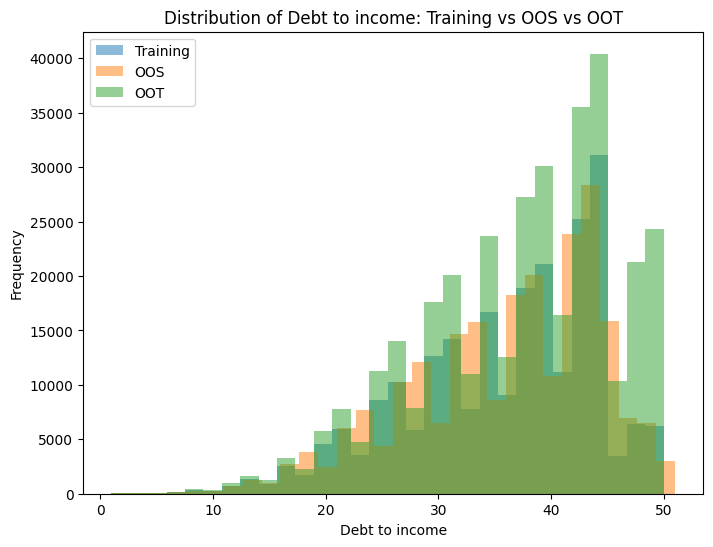

In [ ]:
#Comparing distribustions visually
#Debt_to_income

plt.figure(figsize=(8, 6))

plt.hist(
    training_data["Debt_to_income"].dropna(),
    bins=30,
    alpha=0.5,
    label="Training"
)

plt.hist(
    OOS_data["Debt_to_income"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOS"
)

plt.hist(
    OOT_data["Debt_to_income"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOT"
)

plt.title("Distribution of Debt to income: Training vs OOS vs OOT")
plt.xlabel("Debt to income")
plt.ylabel("Frequency")
plt.legend()
plt.show()

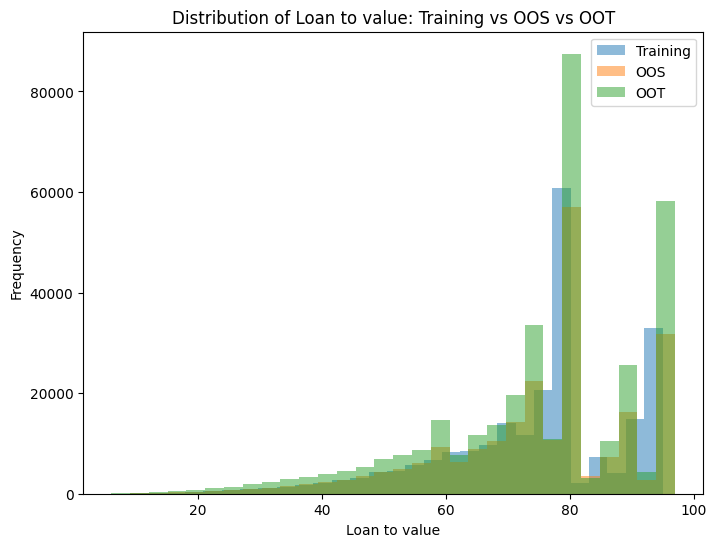

In [ ]:
#Comparing distribustions visually
#OLoan_to_value

plt.figure(figsize=(8, 6))

plt.hist(
    training_data["OLoan_to_value"].dropna(),
    bins=30,
    alpha=0.5,
    label="Training"
)

plt.hist(
    OOS_data["OLoan_to_value"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOS"
)

plt.hist(
    OOT_data["OLoan_to_value"].dropna(),
    bins=30,
    alpha=0.5,
    label="OOT"
)

plt.title("Distribution of Loan to value: Training vs OOS vs OOT")
plt.xlabel("Loan to value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

#5. EDA Conclusion
###The EDA showa that the Dataset has a servere class imbalance, with default observations making up only 0.26% of the training, OOS and OOT dataset.
###This means that accuracy alone would not be a variable measure of model performance.
###The numerical analysis also shows differences between default and non-default loans, particularly for Credit_Score, Debt_to_income,CLoan_to_value and OLoan_to_value.
###Defaulted loans generally have lower credit score and higher debt to income and loan to value measures.
###Default rates also vary across loan purpose, first-time homeowner status, occupacy status and Origination channel-This indicate that these variables may provide useful risk information.
###The Training amd OOS populations are similar for the main numerical predictors, while OOT shows differences- Including a lower average Credit_score and higher average Debt_to_Income and mortgage Insurance.
###Therefore, the modeling process must address class imbalances and evaluate model stability on bot OOS and OOT data.

#Part C - Predictive Modelling

In [ ]:
TARGET = "DFlag"
ID_COL = "Loanref"

# Separate X and Y
X = training_data.drop(columns=[TARGET, ID_COL])
y = training_data[TARGET]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('X_train shape:', X_train.shape)
print('X_val shape:', X_val.shape)
print('y_train shape:', y_train.mean())
print('y_val shape:', y_val.mean())

X_train shape: (184851, 78)
X_val shape: (46213, 78)
y_train shape: 0.0025588176423173258
y_val shape: 0.002553394066604635


Some variables contain missing values (NaN). We replace these missing values with the median of each column before training the models.

In [ ]:
from sklearn.impute import SimpleImputer

# Replace missing values with the median
imputer = SimpleImputer(strategy="median")

# Fit the imputer on the training data
# Apply the same transformation to the validation data
X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)

#Feature scaling for Logistic Regression

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)

print('Scaled training shape:', X_train_scaled.shape)
print('Scaled val shape:', X_val_scaled.shape)

Scaled training shape: (184851, 78)
Scaled val shape: (46213, 78)


In [ ]:
X_val_scaled

array([[-0.03980012, -0.57130775, -0.12304343, ..., -0.13173067,
        -0.05624829, -0.04222541],
       [ 1.12365227,  0.45646907, -0.12304343, ..., -0.13173067,
        -0.05624829, -0.04222541],
       [-0.54396281, -0.57130775, -0.12304343, ..., -0.13173067,
        -0.05624829, -0.04222541],
       ...,
       [-0.03980012, -0.57130775, -0.12304343, ..., -0.13173067,
        -0.05624829, -0.04222541],
       [-0.07858186, -0.57130775, -0.12304343, ..., -0.13173067,
        -0.05624829, -0.04222541],
       [-0.85421678, -0.57130775, -0.12304343, ..., -0.13173067,
        -0.05624829, -0.04222541]])

In [ ]:
# Calculate weights using development data only
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Compute class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Store weights in dictionary
class_weights = {0: class_weights[0], 1: class_weights[1]}

print("Class Weights:")
print(class_weights)

Class Weights:
{0: np.float64(0.5012826909935025), 1: np.float64(195.40274841437633)}


In [ ]:
from xgboost import XGBClassifier

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg / pos

print("XGBoost scale_pos_weight: ", scale_pos_weight)

#XGBClassifier
xgb = XGBClassifier(
    eval_metric='logloss',
    n_jobs=-1,
    max_depth=5,
    learning_rate=0.05,
    n_estimators=300,
    subsample=0.08,
    colsample_bytree=0.08,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
)
print('XGBoost trained successfully')

XGBoost scale_pos_weight:  389.80549682875267
XGBoost trained successfully


In [ ]:
# Logistic Regression
log_reg = LogisticRegression(max_iter=2000, class_weight=class_weights, random_state=42)
log_reg.fit(X_train_scaled, y_train)   # learning from the 80%

log_reg_pred = log_reg.predict(X_val_scaled)  # predicting from the 20% test
log_reg_prob = log_reg.predict_proba(X_val_scaled)[:, 1]

print('Logistic Regression trained successfully')

Logistic Regression trained successfully


In [ ]:
# Random Forest
random_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
random_forest.fit(X_train, y_train)

random_forest_pred = random_forest.predict(X_val)
random_forest_prob = random_forest.predict_proba(X_val)[:, 1]

print('Random Forest trained successfully')

Random Forest trained successfully


#Benchmark models the 3 models
XGBoost was chosen as the main model because real-world credit datasets are rarely linear. Financial data frequently features complex, non-linear relationships such as non-proportional risk across different income levels  along with numerous binary flag variables. XGBoost is excellent at capturing these complex feature interactions and non-linear patterns without having to manually build complex variables.

In [ ]:
pipelines = {
    "Logistic Regression": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', log_reg)
    ]),
    "Random Forest": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', random_forest)
    ]),
    "XGBoost": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', xgb)
    ])
}

# 2.metric calculation function using passed X_eval and y_eval
def metric_row(name, model, X_eval, y_eval, threshold=0.50):
    p = model.predict_proba(X_eval)[:, 1]
    pred = (p >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, p),
        "PR-AUC": average_precision_score(y_eval, p)
    }

# 3. Fit models and compute validation metrics
validation_results = []
fitted_models = {}

for name, pipe in pipelines.items():
    # Fit pipeline on training data
    fitted_pipe = clone(pipe).fit(X_train, y_train)
    fitted_models[name] = fitted_pipe

    # Evaluate on validation data
    validation_results.append(
        metric_row(name, fitted_pipe, X_val, y_val, threshold=0.50)
    )

validation_results = pd.DataFrame(validation_results)
display(validation_results.sort_values("PR-AUC", ascending=False))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.5,0.720858,0.006943,0.762712,0.013761,0.793904,0.014585
2,XGBoost,0.5,0.751953,0.006181,0.601695,0.012236,0.730816,0.008683
1,Random Forest,0.5,0.997403,0.000000,0.000000,0.000000,0.612978,0.005200


#Hyperparameter Tuning for the main model

In [ ]:
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": [150, 250, 350, 500],
    "model__learning_rate": [0.02, 0.05, 0.08, 0.12],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__reg_lambda": [0.5, 1.0, 2.0, 5.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_train, y_train)

print("Best development CV PR-AUC:", xgb_search.best_score_)
print("Best parameters:")
print(xgb_search.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best development CV PR-AUC: 0.011770894559080742
Best parameters:
{'model__subsample': 0.9, 'model__reg_lambda': 5.0, 'model__n_estimators': 150, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.02, 'model__colsample_bytree': 0.8}


#Validation Threshold Selection

In [ ]:
main_model = xgb_search.best_estimator_

val_prob = main_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, val_prob)
f1_values = 2 * precisions[:-1] * recalls[:-1] / (
    precisions[:-1] + recalls[:-1] + 1e-12
)

best_idx = np.argmax(f1_values)
selected_threshold = thresholds[best_idx]

print("Selected validation threshold:", selected_threshold)
print("Validation precision:", precisions[best_idx])
print("Validation recall:", recalls[best_idx])
print("Validation F1:", f1_values[best_idx])


Selected validation threshold: 0.8129518
Validation precision: 0.05555555555555555
Validation recall: 0.05084745762711865
Validation F1: 0.05309734513224434


In [ ]:
def threshold_metrics(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob)
    }

threshold_comparison = pd.DataFrame([
    threshold_metrics(y_val, val_prob, 0.50),
    threshold_metrics(y_val, val_prob, selected_threshold)
], index=["Default 0.50", "Selected threshold"])

display(threshold_comparison)


,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Default 0.50,0.500000,0.717439,0.006860,0.762712,0.013597,0.804468,0.014488
Selected threshold,0.812952,0.995369,0.055556,0.050847,0.053097,0.804468,0.014488


#Business Cost & Trade-off Analysis:

###1.   False Negatives (FN) - High Risk (Underwriting Default Risk):

*   **Definition**:A False Negative occurs when a borrower defaults, they are mistakenly labelled as safe and given credit.
*   **Financial Impact**:False Negatives display the most damaging financial outcome in credit risk modeling. When a borrower defaults on a loan, the lender is forced to write off the outstanding amount, which causes a direct financial loss.

###2.   False Positives (FP) - Low Risk (Opportunity Cost & Friction):

*  **Definition**: A False Positive occurs when an applicant with good credit who would repay the loan is mistakenly labelled as high risk and turned down.
*   **Financial Impact**: represents potential customer churn to rival lenders, lost interest income, and friction in client acquisition costs.

###3. Threshold Selection Justification:

*   More applicants are categorised as default risks when the threshold is lowered. This raises false positives (rejecting safe customers), but it also promotes recall by identifying problematic loans. Increasing the threshold has the opposite effect. In the end, the operational threshold needs to weigh the lost revenue from an unwarranted rejection against the financial impact of a missed default.







#Refit the final main model on the full training set

In [ ]:
final_training_model = clone(main_model).fit(X, y)

print("Final training-only model fitted on:", X.shape)
print("Operating threshold retained from validation:", selected_threshold)

Final training-only model fitted on: (231064, 78)
Operating threshold retained from validation: 0.8129518


In [ ]:
# Refit the benchmark models on the FULL training.csv, same principle as final_training_model
final_log_reg_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000, class_weight=class_weights, random_state=42))
])
final_log_reg = final_log_reg_pipeline.fit(X, y)

final_rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1
    ))
])
final_rf = final_rf_pipeline.fit(X, y)

print("Final Logistic Regression and Random Forest refit on full training set:", X.shape)

Final Logistic Regression and Random Forest refit on full training set: (231064, 78)


#Part D – Model Evaluation

1. Model Comparison Table(OOS & OOT)

In [ ]:
# Build the OOS and OOT predictor/target sets using the SAME columns as training
# Split OOS file into features (X) and target (y), dropping target + ID column

X_oos = OOS_data.drop(columns=[TARGET, ID_COL])
y_oos = OOS_data[TARGET]

# Same split for the OOT file
X_oot = OOT_data.drop(columns=[TARGET, ID_COL])
y_oot = OOT_data[TARGET]

print("X_oos shape:", X_oos.shape, "| default rate:", round(y_oos.mean() * 100, 4), "%")
print("X_oot shape:", X_oot.shape, "| default rate:", round(y_oot.mean() * 100, 4), "%")


X_oos shape: (232515, 78) | default rate: 0.2563 %
X_oot shape: (352788, 78) | default rate: 0.2625 %


In [ ]:


# Split OOS file into features (X) and target (y), dropping target + ID column
X_oos = OOS_data.drop(columns=[TARGET, ID_COL])
y_oos = OOS_data[TARGET]

# Same split for the OOT file
X_oot = OOT_data.drop(columns=[TARGET, ID_COL])
y_oot = OOT_data[TARGET]

# Sanity check: confirm shapes and default rates look as expected
print("X_oos shape:", X_oos.shape, "| default rate:", round(y_oos.mean() * 100, 4), "%")
print("X_oot shape:", X_oot.shape, "| default rate:", round(y_oot.mean() * 100, 4), "%")


X_oos shape: (232515, 78) | default rate: 0.2563 %
X_oot shape: (352788, 78) | default rate: 0.2625 %


In [ ]:


# Split OOS file into features (X) and target (y), dropping target + ID column
X_oos = OOS_data.drop(columns=[TARGET, ID_COL])
y_oos = OOS_data[TARGET]

# Same split for the OOT file
X_oot = OOT_data.drop(columns=[TARGET, ID_COL])
y_oot = OOT_data[TARGET]

# Sanity check: confirm shapes and default rates look as expected
print("X_oos shape:", X_oos.shape, "| default rate:", round(y_oos.mean() * 100, 4), "%")
print("X_oot shape:", X_oot.shape, "| default rate:", round(y_oot.mean() * 100, 4), "%")


X_oos shape: (232515, 78) | default rate: 0.2563 %
X_oot shape: (352788, 78) | default rate: 0.2625 %


In [ ]:
# Probabilities from the three FINAL models (each refit on the full training.csv)
xgb_prob_oos = final_training_model.predict_proba(X_oos)[:, 1]
log_reg_prob_oos = final_log_reg.predict_proba(X_oos)[:, 1]
rf_prob_oos = final_rf.predict_proba(X_oos)[:, 1]

xgb_prob_oot = final_training_model.predict_proba(X_oot)[:, 1]
log_reg_prob_oot = final_log_reg.predict_proba(X_oot)[:, 1]
rf_prob_oot = final_rf.predict_proba(X_oot)[:, 1]

# Hard class labels
# - Main model (XGBoost) uses the threshold selected on validation data
# - Benchmarks use the conventional 0.50 threshold, since threshold selection
#   in this assignment is only required for the main model
xgb_pred_oos = (xgb_prob_oos >= selected_threshold).astype(int)
log_reg_pred_oos = (log_reg_prob_oos >= 0.50).astype(int)
rf_pred_oos = (rf_prob_oos >= 0.50).astype(int)

xgb_pred_oot = (xgb_prob_oot >= selected_threshold).astype(int)
log_reg_pred_oot = (log_reg_prob_oot >= 0.50).astype(int)
rf_pred_oot = (rf_prob_oot >= 0.50).astype(int)

model_names = ["XGBoost (main)", "Logistic Regression", "Random Forest"]

print("Predictions generated for OOS and OOT for all three final models.")

Predictions generated for OOS and OOT for all three final models.


In [ ]:

# 1. OUT-OF-SAMPLE (OOS) EVALUATION TABLE
all_predictions_oos = [
    xgb_pred_oos,
    log_reg_pred_oos,
    rf_pred_oos
]

all_probabilities_oos = [
    xgb_prob_oos,
    log_reg_prob_oos,
    rf_prob_oos
]

accuracy_values_oos = []
precision_values_oos = []
recall_values_oos = []
f1_values_oos = []
roc_auc_values_oos = []
aupr_values_oos = []

for i in range(len(model_names)):
    accuracy_values_oos.append(accuracy_score(y_oos, all_predictions_oos[i]))
    precision_values_oos.append(precision_score(y_oos, all_predictions_oos[i], zero_division=0))
    recall_values_oos.append(recall_score(y_oos, all_predictions_oos[i], zero_division=0))
    f1_values_oos.append(f1_score(y_oos, all_predictions_oos[i], zero_division=0))
    roc_auc_values_oos.append(roc_auc_score(y_oos, all_probabilities_oos[i]))
    aupr_values_oos.append(average_precision_score(y_oos, all_probabilities_oos[i]))

evaluation_table_oos = pd.DataFrame({
    'Model': model_names,
    'Accuracy': accuracy_values_oos,
    'Precision': precision_values_oos,
    'Recall': recall_values_oos,
    'F1 Score': f1_values_oos,
    'AUROC': roc_auc_values_oos,
    'AUPR': aupr_values_oos
}).sort_values(by='AUPR', ascending=False)

print("--- Out-of-Sample (OOS) Evaluation Table ---")
display(evaluation_table_oos.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1 Score': '{:.4f}',
    'AUROC': '{:.4f}',
    'AUPR': '{:.4f}'
}))


# 2. OUT-OF-TIME (OOT) EVALUATION TABLE
all_predictions_oot = [
    xgb_pred_oot,
    log_reg_pred_oot,
    rf_pred_oot
]

all_probabilities_oot = [
    xgb_prob_oot,
    log_reg_prob_oot,
    rf_prob_oot
]

accuracy_values_oot = []
precision_values_oot = []
recall_values_oot = []
f1_values_oot = []
roc_auc_values_oot = []
aupr_values_oot = []

for i in range(len(model_names)):
    accuracy_values_oot.append(accuracy_score(y_oot, all_predictions_oot[i]))
    precision_values_oot.append(precision_score(y_oot, all_predictions_oot[i], zero_division=0))
    recall_values_oot.append(recall_score(y_oot, all_predictions_oot[i], zero_division=0))
    f1_values_oot.append(f1_score(y_oot, all_predictions_oot[i], zero_division=0))
    roc_auc_values_oot.append(roc_auc_score(y_oot, all_probabilities_oot[i]))
    aupr_values_oot.append(average_precision_score(y_oot, all_probabilities_oot[i]))

evaluation_table_oot = pd.DataFrame({
    'Model': model_names,
    'Accuracy': accuracy_values_oot,
    'Precision': precision_values_oot,
    'Recall': recall_values_oot,
    'F1 Score': f1_values_oot,
    'AUROC': roc_auc_values_oot,
    'AUPR': aupr_values_oot
}).sort_values(by='AUPR', ascending=False)

print("\n--- Out-of-Time (OOT) Evaluation Table ---")
display(evaluation_table_oot.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1 Score': '{:.4f}',
    'AUROC': '{:.4f}',
    'AUPR': '{:.4f}'
}))

--- Out-of-Sample (OOS) Evaluation Table ---


,Model,Accuracy,Precision,Recall,F1 Score,AUROC,AUPR
1,Logistic Regression,0.7250,0.0063,0.6795,0.0125,0.7655,0.0102
0,XGBoost (main),0.9944,0.0231,0.0285,0.0255,0.7718,0.0096
2,Random Forest,0.9974,0.0455,0.0017,0.0032,0.5953,0.0042



--- Out-of-Time (OOT) Evaluation Table ---


,Model,Accuracy,Precision,Recall,F1 Score,AUROC,AUPR
0,XGBoost (main),0.9940,0.0083,0.0108,0.0094,0.7219,0.0063
1,Logistic Regression,0.6689,0.0050,0.6307,0.0099,0.7027,0.0059
2,Random Forest,0.9973,0.0000,0.0000,0.0000,0.5693,0.0033


## Interpretion of the comparison table

# 2. Confusion Matrices and Classification Reports (Main Model vs Strongest Benchmark)

Using the validation results table, Logistic Regression had the best PR-AUC among the two benchmarks, resulting in it being used as the "strongest benchmark". XGBoost is the main model.

=== XGBoost (Main Model) - OOS ===


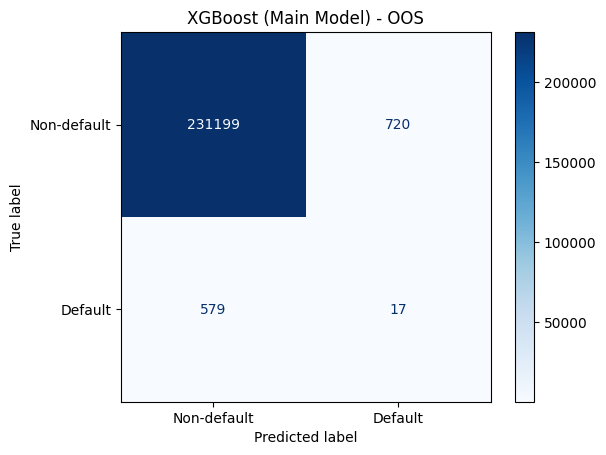

              precision    recall  f1-score   support

 Non-default       1.00      1.00      1.00    231919
     Default       0.02      0.03      0.03       596

    accuracy                           0.99    232515
   macro avg       0.51      0.51      0.51    232515
weighted avg       1.00      0.99      0.99    232515


=== XGBoost (Main Model) - OOT ===


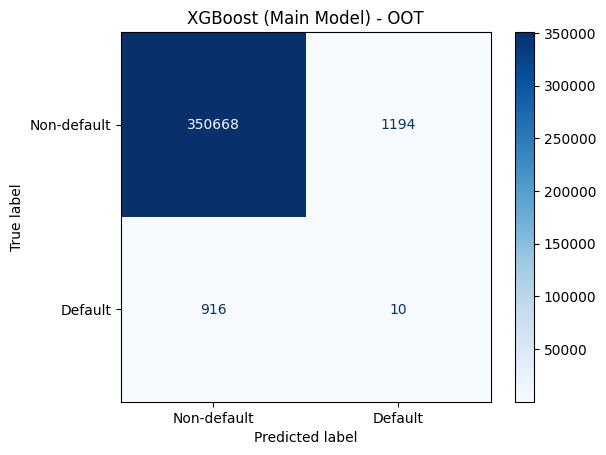

              precision    recall  f1-score   support

 Non-default       1.00      1.00      1.00    351862
     Default       0.01      0.01      0.01       926

    accuracy                           0.99    352788
   macro avg       0.50      0.50      0.50    352788
weighted avg       0.99      0.99      0.99    352788


=== Logistic Regression (Strongest Benchmark) - OOS ===


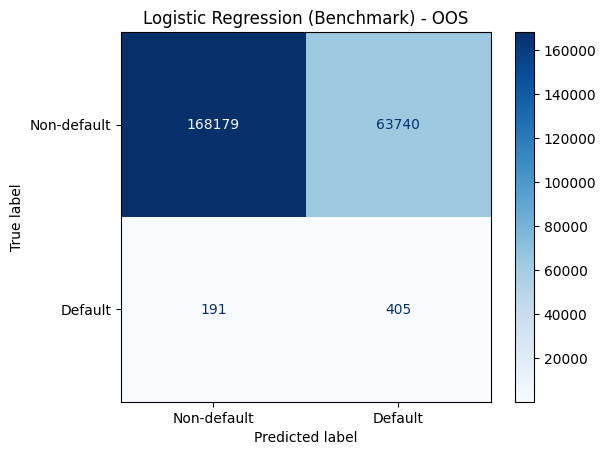

              precision    recall  f1-score   support

 Non-default       1.00      0.73      0.84    231919
     Default       0.01      0.68      0.01       596

    accuracy                           0.73    232515
   macro avg       0.50      0.70      0.43    232515
weighted avg       1.00      0.73      0.84    232515


=== Logistic Regression (Strongest Benchmark) - OOT ===


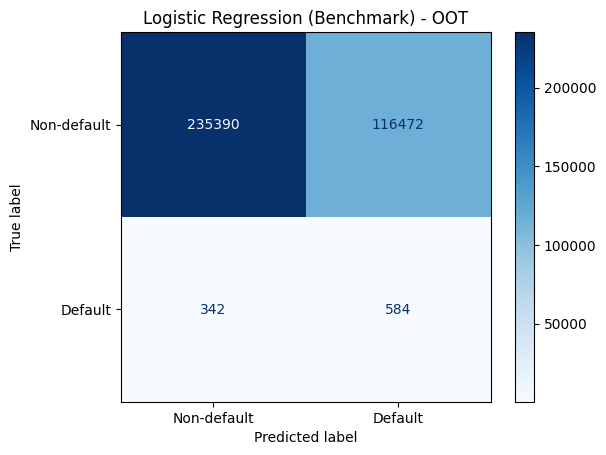

              precision    recall  f1-score   support

 Non-default       1.00      0.67      0.80    351862
     Default       0.00      0.63      0.01       926

    accuracy                           0.67    352788
   macro avg       0.50      0.65      0.41    352788
weighted avg       1.00      0.67      0.80    352788



In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-default", "Default"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(title)
    plt.show()
    return cm

print("=== XGBoost (Main Model) - OOS ===")
cm_xgb_oos = plot_confusion(y_oos, xgb_pred_oos, "XGBoost (Main Model) - OOS")
print(classification_report(y_oos, xgb_pred_oos, target_names=["Non-default", "Default"], zero_division=0))

print("\n=== XGBoost (Main Model) - OOT ===")
cm_xgb_oot = plot_confusion(y_oot, xgb_pred_oot, "XGBoost (Main Model) - OOT")
print(classification_report(y_oot, xgb_pred_oot, target_names=["Non-default", "Default"], zero_division=0))

print("\n=== Logistic Regression (Strongest Benchmark) - OOS ===")
cm_log_oos = plot_confusion(y_oos, log_reg_pred_oos, "Logistic Regression (Benchmark) - OOS")
print(classification_report(y_oos, log_reg_pred_oos, target_names=["Non-default", "Default"], zero_division=0))

print("\n=== Logistic Regression (Strongest Benchmark) - OOT ===")
cm_log_oot = plot_confusion(y_oot, log_reg_pred_oot, "Logistic Regression (Benchmark) - OOT")
print(classification_report(y_oot, log_reg_pred_oot, target_names=["Non-default", "Default"], zero_division=0))


## Interpreting false positives and false negatives



# 3. ROC and Precision-Recall Curves

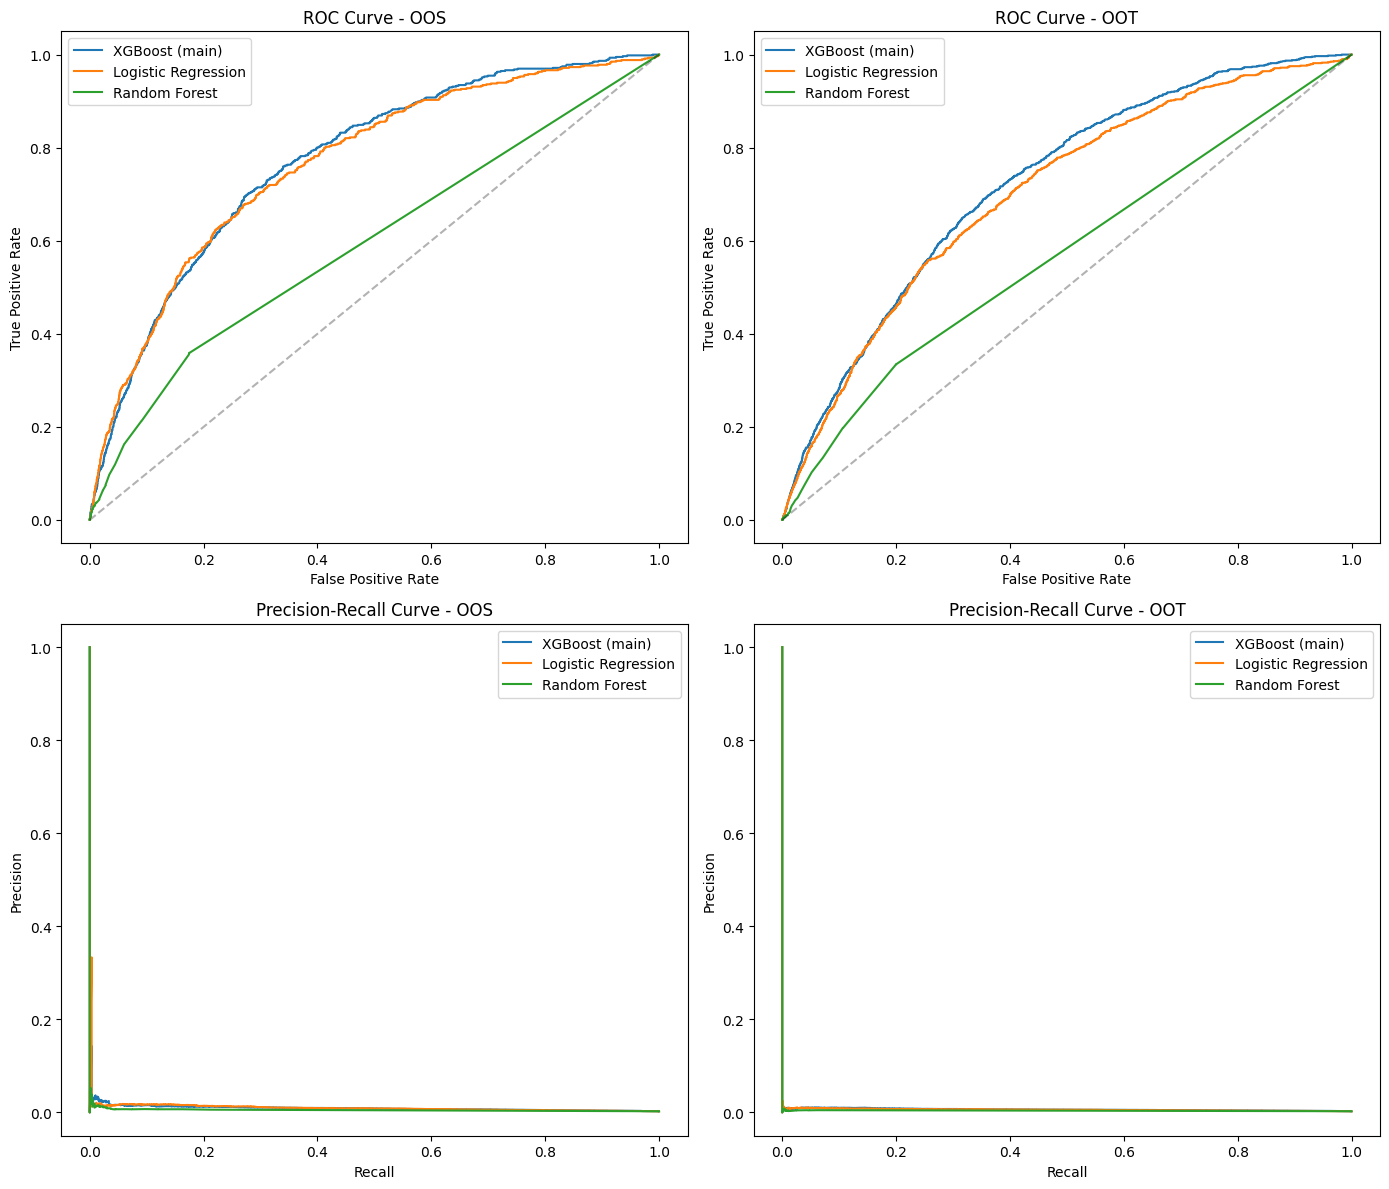

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

all_probabilities_oos = [xgb_prob_oos, log_reg_prob_oos, rf_prob_oos]
all_probabilities_oot = [xgb_prob_oot, log_reg_prob_oot, rf_prob_oot]

# ROC - OOS
for name, prob in zip(model_names, all_probabilities_oos):
    fpr, tpr, _ = roc_curve(y_oos, prob)
    axes[0, 0].plot(fpr, tpr, label=name)
axes[0, 0].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[0, 0].set_title("ROC Curve - OOS")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend()

# ROC - OOT
for name, prob in zip(model_names, all_probabilities_oot):
    fpr, tpr, _ = roc_curve(y_oot, prob)
    axes[0, 1].plot(fpr, tpr, label=name)
axes[0, 1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[0, 1].set_title("ROC Curve - OOT")
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend()

# Precision-Recall - OOS
for name, prob in zip(model_names, all_probabilities_oos):
    prec, rec, _ = precision_recall_curve(y_oos, prob)
    axes[1, 0].plot(rec, prec, label=name)
axes[1, 0].set_title("Precision-Recall Curve - OOS")
axes[1, 0].set_xlabel("Recall")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].legend()

# Precision-Recall - OOT
for name, prob in zip(model_names, all_probabilities_oot):
    prec, rec, _ = precision_recall_curve(y_oot, prob)
    axes[1, 1].plot(rec, prec, label=name)
axes[1, 1].set_title("Precision-Recall Curve - OOT")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## Why Precision-Recall matters more here

## Comparing OOS vs OOT with accuracy and log-loss

,Model,Accuracy_OOS,Accuracy_OOT,LogLoss_OOS,LogLoss_OOT
0,XGBoost (main),0.9944,0.9940,0.5442,0.5902
1,Logistic Regression,0.7250,0.6689,0.5463,0.6191
2,Random Forest,0.9974,0.9973,0.0662,0.0701


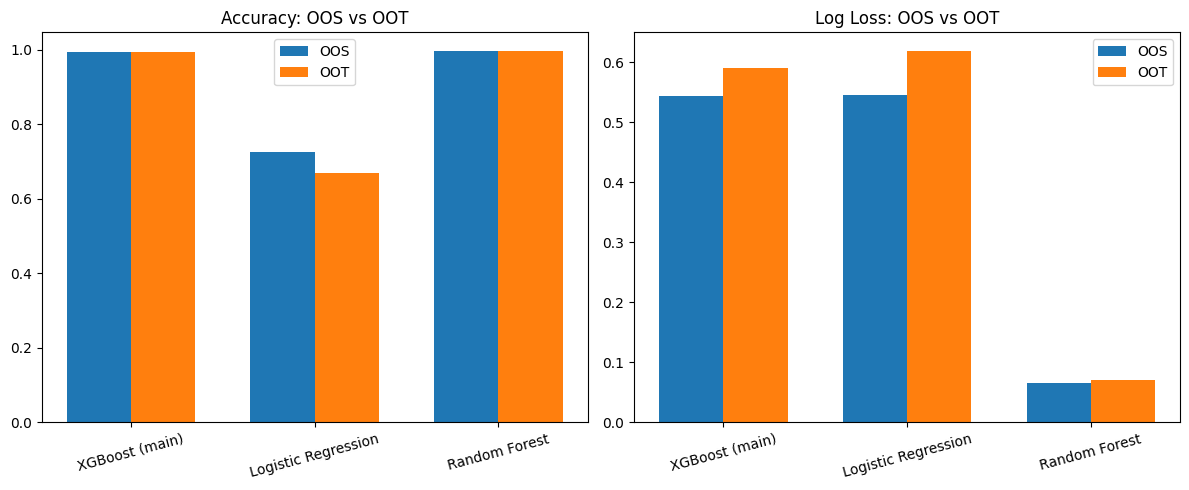

In [ ]:
from sklearn.metrics import log_loss

all_predictions_oos = [xgb_pred_oos, log_reg_pred_oos, rf_pred_oos]
all_predictions_oot = [xgb_pred_oot, log_reg_pred_oot, rf_pred_oot]

comparison_rows = []
for name, pred_oos, prob_oos, pred_oot, prob_oot in zip(
    model_names, all_predictions_oos, all_probabilities_oos, all_predictions_oot, all_probabilities_oot
):
    comparison_rows.append({
        "Model": name,
        "Accuracy_OOS": accuracy_score(y_oos, pred_oos),
        "Accuracy_OOT": accuracy_score(y_oot, pred_oot),
        "LogLoss_OOS": log_loss(y_oos, prob_oos),
        "LogLoss_OOT": log_loss(y_oot, prob_oot)
    })

oos_oot_comparison = pd.DataFrame(comparison_rows)
display(oos_oot_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(len(model_names))
width = 0.35

axes[0].bar(x - width / 2, oos_oot_comparison["Accuracy_OOS"], width, label="OOS")
axes[0].bar(x + width / 2, oos_oot_comparison["Accuracy_OOT"], width, label="OOT")
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=15)
axes[0].set_title("Accuracy: OOS vs OOT")
axes[0].legend()

axes[1].bar(x - width / 2, oos_oot_comparison["LogLoss_OOS"], width, label="OOS")
axes[1].bar(x + width / 2, oos_oot_comparison["LogLoss_OOT"], width, label="OOT")
axes[1].set_xticks(x)
axes[1].set_xticklabels(model_names, rotation=15)
axes[1].set_title("Log Loss: OOS vs OOT")
axes[1].legend()

plt.tight_layout()
plt.show()


# 4. Statistical Significance Testing (Main Model vs Strongest Benchmark)
Paired 5-fold stratified cross-validation on training.csv, comparing PR-AUC (AUPR) for the tuned XGBoost pipeline vs the Logistic Regression pipeline.

In [ ]:
from scipy import stats

cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

main_fold_scores = []
benchmark_fold_scores = []

for fold_idx, (train_idx, test_idx) in enumerate(cv_splitter.split(X, y)):
    X_fold_train, X_fold_test = X.iloc[train_idx], X.iloc[test_idx]
    y_fold_train, y_fold_test = y.iloc[train_idx], y.iloc[test_idx]

    m_main = clone(xgb_search.best_estimator_).fit(X_fold_train, y_fold_train)
    m_bench = clone(fitted_models["Logistic Regression"]).fit(X_fold_train, y_fold_train)

    p_main = m_main.predict_proba(X_fold_test)[:, 1]
    p_bench = m_bench.predict_proba(X_fold_test)[:, 1]

    main_fold_scores.append(average_precision_score(y_fold_test, p_main))
    benchmark_fold_scores.append(average_precision_score(y_fold_test, p_bench))

    print(f"Fold {fold_idx + 1}: Main PR-AUC = {main_fold_scores[-1]:.4f}  |  Benchmark PR-AUC = {benchmark_fold_scores[-1]:.4f}")

main_fold_scores = np.array(main_fold_scores)
benchmark_fold_scores = np.array(benchmark_fold_scores)

# Paired t-test
t_stat, t_pvalue = stats.ttest_rel(main_fold_scores, benchmark_fold_scores)

# Wilcoxon signed-rank test
w_stat, w_pvalue = stats.wilcoxon(main_fold_scores, benchmark_fold_scores)

alpha = 0.05

print("\nH0: The mean paired difference in PR-AUC between the main model and the strongest benchmark is zero.")
print("H1: The mean paired difference in PR-AUC between the main model and the strongest benchmark is not zero.")
print(f"Alpha = {alpha}\n")

print(f"Paired t-test:  t = {t_stat:.4f}, p = {t_pvalue:.4f}")
print(f"Wilcoxon test:  W = {w_stat:.4f}, p = {w_pvalue:.4f}")

t_conclusion = "reject H0" if t_pvalue < alpha else "fail to reject H0"
w_conclusion = "reject H0" if w_pvalue < alpha else "fail to reject H0"

print(f"\nPaired t-test conclusion: {t_conclusion}")
print(f"Wilcoxon test conclusion: {w_conclusion}")


Fold 1: Main PR-AUC = 0.0089  |  Benchmark PR-AUC = 0.0086
Fold 2: Main PR-AUC = 0.0113  |  Benchmark PR-AUC = 0.0110
Fold 3: Main PR-AUC = 0.0204  |  Benchmark PR-AUC = 0.0247
Fold 4: Main PR-AUC = 0.0165  |  Benchmark PR-AUC = 0.0145
Fold 5: Main PR-AUC = 0.0129  |  Benchmark PR-AUC = 0.0121

H0: The mean paired difference in PR-AUC between the main model and the strongest benchmark is zero.
H1: The mean paired difference in PR-AUC between the main model and the strongest benchmark is not zero.
Alpha = 0.05

Paired t-test:  t = -0.1520, p = 0.8866
Wilcoxon test:  W = 5.0000, p = 0.6250

Paired t-test conclusion: fail to reject H0
Wilcoxon test conclusion: fail to reject H0


### Do the two tests agree?

#Part E - Business Insights and Recommendations

1. A false negative occurs when the model predicts that a borrower will not default but the borrower actually defaults. The lender sees the mortgage as low risk when the borrower is actually likely to default. The lender can then suffer financial losses because the borrower may stop making payments, leading to arrears, collections costs, recovery costs and potentially a loss on the property.


A false positive occurs when the model predicts that ba borrower will default but the borrower actually doe not default. The lender incorrectly identifies a creditworthy borrower as a high risk borrower. The lender might reject the mortgage application, offeer less favourable terms or subject the borrower to additional risk controls. The lender therefore loses a potentially profitable customer and the associated interest income.

According to our analysis, a false negative is more costly because it can result in a direct credit loss when an actual default is not identified. This is particularly important given the extreme class imbalance in the dataset, where only 0.256% of observations are defaults compared with 99.774% non-defaults. A model could therefore achieve high accuracy while still failing to detect the relatively small number of actual defaults. For this reason, identifying defaults correctly is more important than relying on accuracy alone and measures such as recall should be considered when evaluating the model.



2. Recommended model and operating threshold

Based on our OOS and OOT results, we recommend Logistic Regression as the model for deployment, using a classification threshold of 0.50. The main reason for this recommendation is that Logistic Regression was better at identifying borrowers who actually defaulted. This is important because the lender needs to identify borrowers who may default so that the lender can take action to reduce possible losses.

Although XGBoost had higher accuracy, it did not identify many of the actual defaulters. Its default recall was only 2.85% on the OOS data and 1.08% on the OOT data. This means that most of the borrowers who actually defaulted were predicted as non-defaults.

Logistic Regression had a much higher default recall, identifying 67.95% of the actual defaults in the OOS data and 63.07% in the OOT data. This shows that Logistic Regression was better at finding actual defaulters on both datasets. Its performance did become lower on the OOT data, but it still identified more actual defaults than XGBoost. Therefore, we recommend Logistic Regression at a threshold of 0.50 because it gives the lender a better chance of identifying borrowers who may default.


3. Four actionable risk insights

The analysis provides several useful risk insights for the lender.

1. Default detection should be prioritised over accuracy. The default rate is only about 0.26%, meaning that most borrowers do not default. Because of this, a model can have very high accuracy while still missing many actual defaulters. The lender should therefore also look at measures such as recall, precision and PR-AUC when checking the model.

2. The current XGBoost threshold misses most actual defaulters. XGBoost had a default recall of only 2.85% on OOS and 1.08% on OOT. This means that the threshold of 0.8129518 is very strict and causes many actual defaulters to be classified as non-defaulters. The lender should therefore consider reviewing the threshold if XGBoost is used in the future.

3. Logistic Regression is currently better at identifying possible defaulters. Logistic Regression achieved a default recall of 67.95% on OOS and 63.07% on OOT. This means that it identifies a much larger proportion of borrowers who actually defaulted. The lender can therefore use it to identify borrowers who may need more attention or further credit-risk checks.

4. The models perform worse on newer data. XGBoost ROC-AUC decreased from 0.7718 on OOS to 0.7219 on OOT, while Logistic Regression decreased from 0.7655 to 0.7027. This shows that the models do not perform as well when they are tested on newer data. The lender should therefore continue monitoring the model and check whether changes in the borrowers or economic conditions are affecting its performance.

4. 12-month monitoring plan

The lender should monitor both the model's performance and the data it uses during the first 12 months after deployment.

Months 1–3: The model should be checked every month using measures such as default recall, precision, F1-score, PR-AUC and false-negative rate. These results should be compared with the original OOS and OOT results. The lender should also monitor the overall default rate and the number of borrowers classified as high risk.

Months 4–6: The lender should focus more on checking whether the data has changed. Important variables should be compared with the training and OOS data to see whether their values or distributions have changed. If large changes are found, the lender should investigate why they are happening.

Months 7–9: By this stage, more actual repayment results should be available. The lender should test the model again using these new results. Measures such as recall, precision and PR-AUC should be compared with the original OOS and OOT results. If the model is becoming worse at identifying defaults, it should be reviewed.

Months 10–12: A full review of the model should be done after one year. The lender should consider retraining or changing the model if recall or PR-AUC decreases significantly, the false-negative rate increases, the default rate changes significantly, or important variables show continued changes. If the model continues to perform worse over time, further investigation should be done.

5. Limitations

 limitations to the analysis.

1. Severe class imbalance: Defaults make up only about 0.26% of the observations. This makes it difficult for the models to identify the smaller default group. It also means that accuracy can make the model look better than it actually is.

2. Limited information: The models can only use the variables available in the dataset. There may be other factors that affect whether a borrower defaults that are not included in the data. This can limit the model's ability to identify all high-risk borrowers.

3. Performance changes over time: Both models had lower ROC-AUC on the OOT data compared with the OOS data. This shows that the models may not perform exactly the same when they are used on newer borrowers or data.

4. The results do not show cause and effect: The variables used by the models can help predict default risk, but this does not mean that they directly cause a borrower to default. They should therefore be seen as indicators of risk rather than direct causes of default.

5. Threshold limitations: The XGBoost threshold of 0.8129518 was selected using validation data. However, the best threshold may change depending on the borrower population and the cost of making incorrect predictions. The lender should therefore continue monitoring the threshold after deployment.

Reference

Mushava, J. (2023) 'Credit scoring with class imbalance data: An out-of-sample and out
of-time perspective.' Mendeley Data, V3. doi: 10.17632/bzr2rxttvz.3.